In [1]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
FILE_PATH = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection/data/icarus_numi_numu_mc_onbeam_offbeam_syst_ppfx.root"

f = uproot.open(FILE_PATH)

# Check what's in detsys_results
detsys_keys = [k for k in f.keys() if 'detsys' in k and 'spline' not in k]

In [2]:
POT = 7.79e20

def get_hist(key):
    h = f[key]
    values, edges = h.to_numpy()
    centers = 0.5 * (edges[:-1] + edges[1:])
    widths = np.diff(edges)
    errors = np.sqrt(h.variances()) if h.variances() is not None else np.sqrt(values)
    # Convert from candidates/1e18 POT to actual event counts
    scale = POT / 1e18
    return centers, widths, values * scale, errors * scale

centers, widths, nom_vals, nom_errs = get_hist("detsys_results/cv")

print(f"Number of bins: {len(centers)}")
print(f"Bin edges (first/last): {centers[0]:.1f} → {centers[-1]:.1f}")
print(f"Total nominal events: {nom_vals.sum():.1f}")
print(f"Bin centers: {centers}")

Number of bins: 11
Bin edges (first/last): 50.0 → 4500.0
Total nominal events: 99538.7
Bin centers: [  50.  150.  300.  500.  700.  900. 1250. 1750. 2500. 3500. 4500.]


In [3]:
STYLE_PATH = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/style.mplstyle"
plt.style.use(STYLE_PATH)

VAR_INFO = {
    "var01": {"label": "Induction Gain",         "sigma": "1σ",   "one_sided": False},
    "var02": {"label": "TPC Coherent Noise",      "sigma": "4.9%", "one_sided": False},
    "var03": {"label": "TPC Intrinsic Noise",     "sigma": "10%",  "one_sided": False},
    "var04": {"label": "Lifetime",                "sigma": "1σ",   "one_sided": False},
    "var05": {"label": "Scintillation (PMT QE)",  "sigma": "1σ",   "one_sided": True},
    "var06": {"label": "Induction Gap",           "sigma": "1σ",   "one_sided": True},
    "var07": {"label": "YZ Uniformity",           "sigma": "1σ",   "one_sided": True},
    "var08": {"label": "Recombination",           "sigma": "1σ",   "one_sided": True},
    "var09": {"label": "Cathode Bending",         "sigma": "1σ",   "one_sided": True}
}

X_LABEL = r'$\mathbf{Reco\ Leading\ Muon\ KE\ [MeV]}$'
Y_LABEL_TOP = r'$\mathbf{Events\ /\ bin}$'
Y_LABEL_BOT = r'$\mathbf{Var\ /\ CV}$'

In [4]:
def add_icarus_labels(ax):
    yrange = ax.get_ylim()
    xrange = ax.get_xlim()
    usey       = yrange[1] + 0.01 * (yrange[1] - yrange[0])
    usex       = xrange[0] + 0.01 * (xrange[1] - xrange[0])
    usex_right = xrange[1] - 0.025 * (xrange[1] - xrange[0])
    ax.text(usex, usey,
            r'$\bf{ICARUS \cdot NuMI}$ Simulation' + '\n' + 'Work-in-Progress',
            fontsize=10, color="blue",
            verticalalignment="bottom", fontfamily="sans-serif")

def apply_tick_style(ax):
    ax.tick_params(axis='both', which='major', labelsize=12, size=8, width=2, direction='in')
    ax.minorticks_on()
    ax.tick_params(axis='y', which='minor', size=4, width=1, direction='in')
    ax.tick_params(axis='x', which='minor', size=4, width=1, direction='in')
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontfamily('sans-serif')
    ax.yaxis.get_offset_text().set_fontfamily('sans-serif')
    ax.xaxis.get_offset_text().set_fontfamily('sans-serif')


def fill_panels(fig, gs, col, var_vals, var_errs, var_label):
    ax_top = fig.add_subplot(gs[0, col])
    ax_bot = fig.add_subplot(gs[1, col], sharex=ax_top)
    plt.setp(ax_top.get_xticklabels(), visible=False)

    # ── Top panel ──────────────────────────────────────────────────────
    ax_top.errorbar(centers, nom_vals, yerr=nom_errs, xerr=widths/2,
                    fmt='o', markersize=4,
                    markerfacecolor="black", markeredgecolor="black",
                    color="black", capsize=4, capthick=1.5, elinewidth=1.75,
                    linewidth=2, label="CV")
    ax_top.errorbar(centers, var_vals, yerr=var_errs, xerr=widths/2,
                    fmt='o', markersize=4,
                    markerfacecolor="red", markeredgecolor="red",
                    color="red", capsize=4, capthick=1.5, elinewidth=1.75,
                    linewidth=2, label=var_label)

    ax_top.set_ylabel(r'$\mathbf{Events}$', fontsize=12)
    ax_top.legend(fontsize=10)
    ax_top.set_xlim(centers[0] - 50, centers[-1] + 50)
    y_max = np.max(np.concatenate([nom_vals + nom_errs, var_vals + var_errs])) * 1.2
    ax_top.set_ylim(0, y_max)
    ax_top.grid(True, alpha=0.3)
    apply_tick_style(ax_top)
    add_icarus_labels(ax_top)

    # ── Ratio panel ────────────────────────────────────────────────────
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio     = np.where(nom_vals > 0, var_vals / nom_vals, np.nan)
        rel_var   = np.where(var_vals > 0, (var_errs / var_vals)**2, 0)
        rel_nom   = np.where(nom_vals > 0, (nom_errs / nom_vals)**2, 0)
        ratio_err = np.abs(ratio) * np.sqrt(rel_var + rel_nom)

    ax_bot.axhline(y=1, color='black', linestyle='--', linewidth=1.0, alpha=0.8)
    ax_bot.errorbar(centers, ratio, yerr=ratio_err, xerr=widths/2,
                    fmt='o', markersize=4,
                    markerfacecolor='darkblue', markeredgecolor='darkblue',
                    color='darkblue', capsize=4, capthick=1.5, elinewidth=1.75,
                    linewidth=2)
    ax_bot.set_ylabel(r'$\mathbf{Var\ /\ CV}$', fontsize=12)
    ax_bot.set_xlabel(r'$\mathbf{Reco\ Leading\ Muon\ KE\ [MeV]}$', fontsize=12)
    ax_bot.set_ylim(0.7, 1.3)
    ax_bot.grid(True, alpha=0.3)
    apply_tick_style(ax_bot)

    return ax_top, ax_bot


def plot_variation(var_key, info):
    one_sided = info["one_sided"]
    label     = info["label"]
    sigma     = info["sigma"]
    ncols     = 1 if one_sided else 2

    fig = plt.figure(figsize=(6 * ncols, 6))
    fig.set_constrained_layout(False)
    gs = gridspec.GridSpec(2, ncols, figure=fig,
                           height_ratios=[3, 1], hspace=0.05, wspace=0.35)

    if one_sided:
        c, w, v, e = get_hist(f"detsys_results/{var_key}")
        fill_panels(fig, gs, 0, v, e, f"{label} ({sigma})")
    else:
        cp, wp, vp, ep = get_hist(f"detsys_results/{var_key}p")
        cm, wm, vm, em = get_hist(f"detsys_results/{var_key}m")
        fill_panels(fig, gs, 0, vp, ep, f"{label} (+{sigma})")
        fill_panels(fig, gs, 1, vm, em, f"{label} (-{sigma})")

    SAVE_DIR = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection/ICARUS-NuMI-CC0pi-Selection/spineplot/myAnalysis/1muNp0pi_Nge1_uncontained/DetSys_Plots"
    import os
    os.makedirs(SAVE_DIR, exist_ok=True)
    fig.savefig(os.path.join(SAVE_DIR, f"pdf/{var_key}_vs_CV.pdf"), dpi=300, bbox_inches='tight')
    fig.savefig(os.path.join(SAVE_DIR, f"jpeg/{var_key}_vs_CV.jpeg"), dpi=300, bbox_inches='tight')
    plt.show()

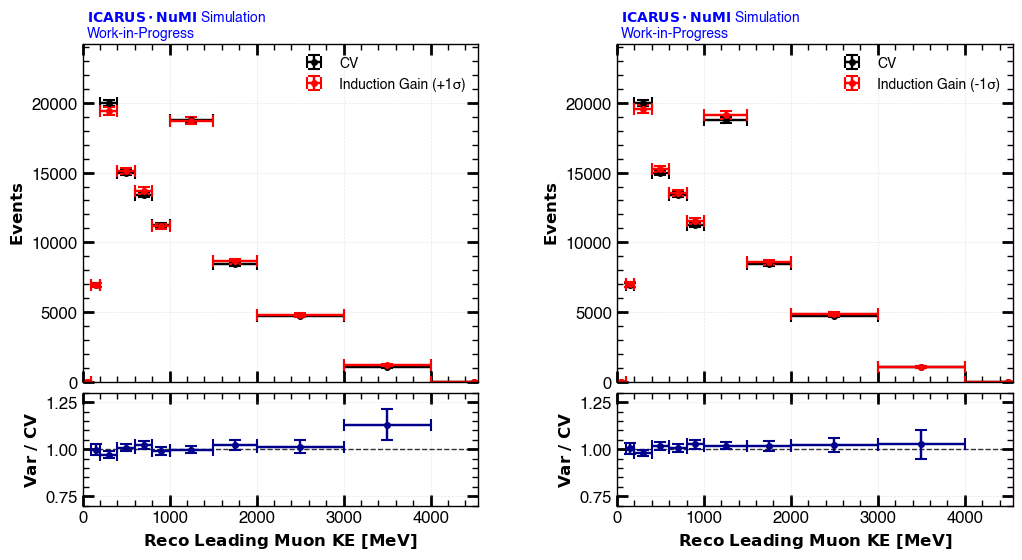

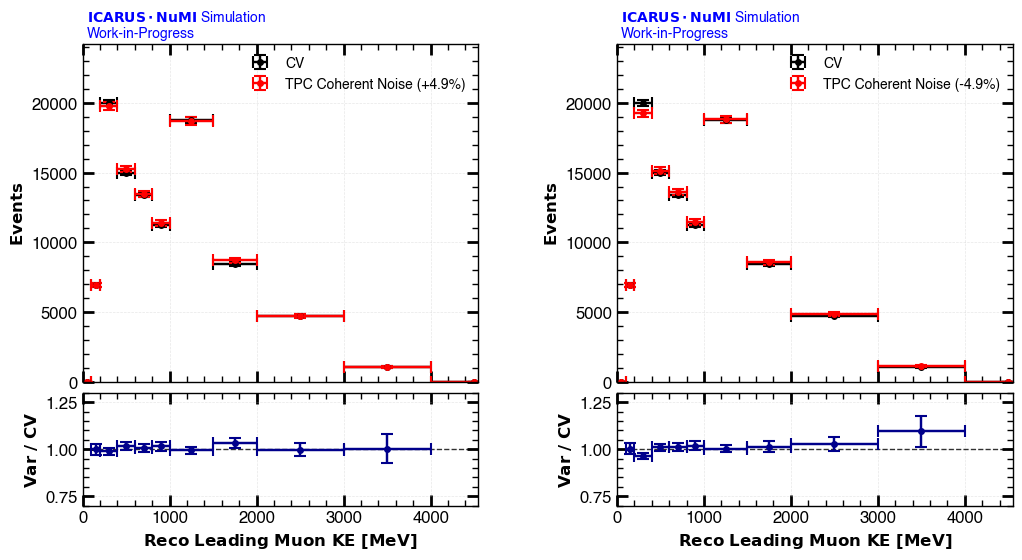

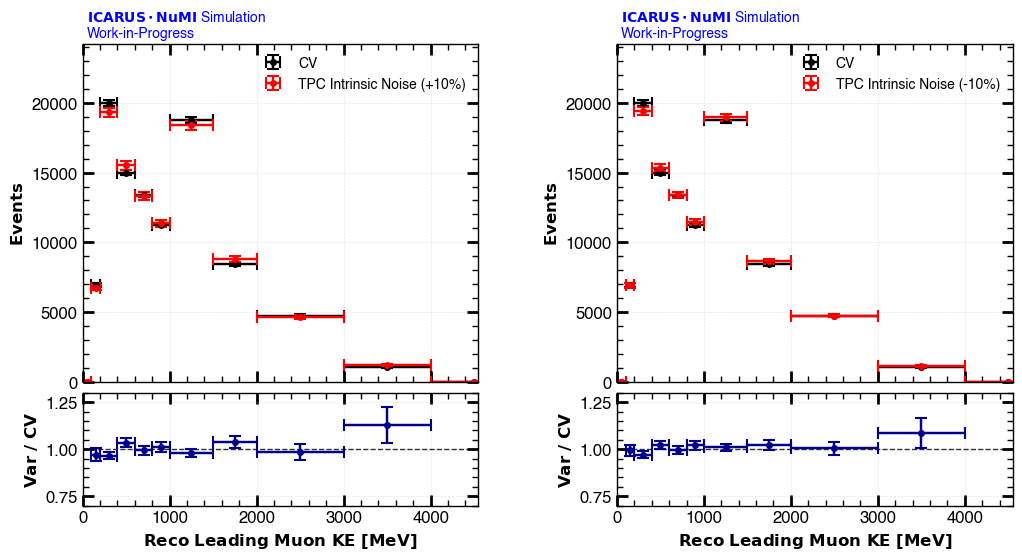

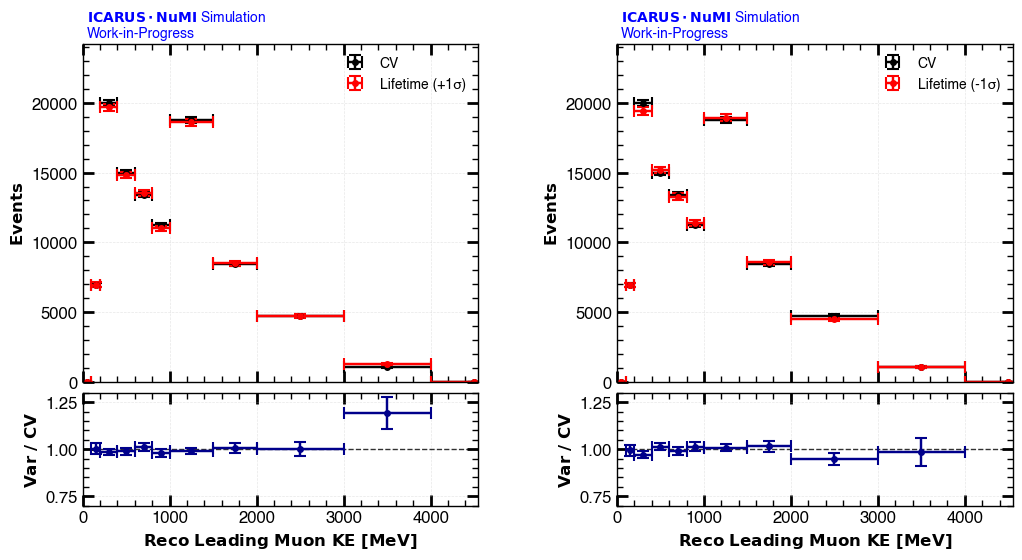

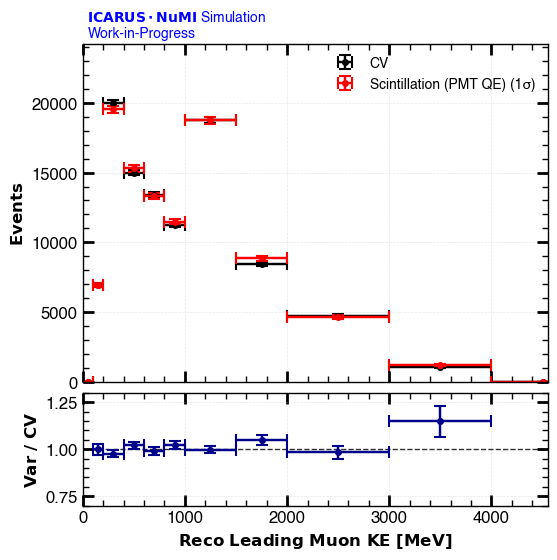

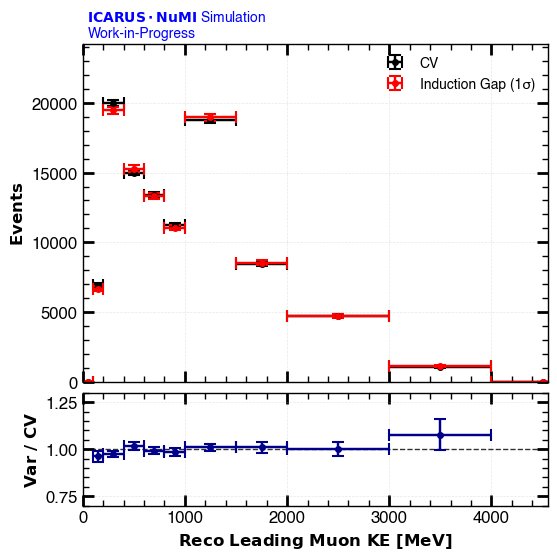

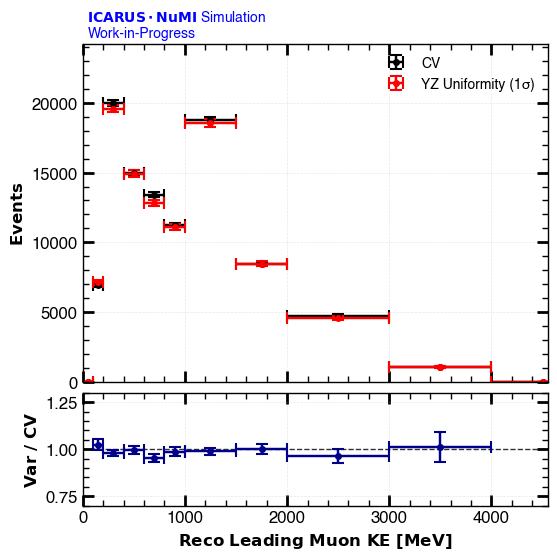

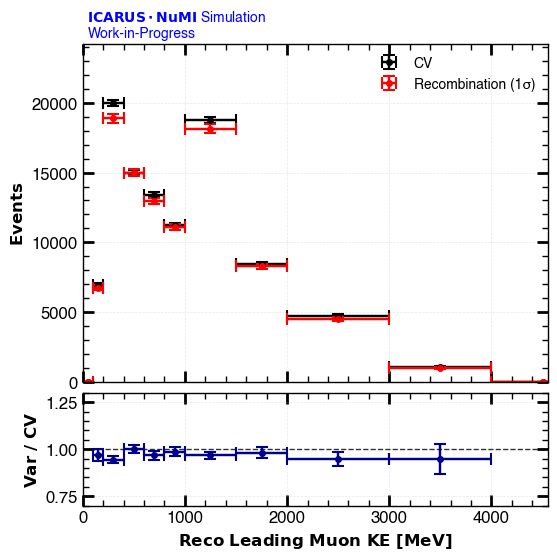

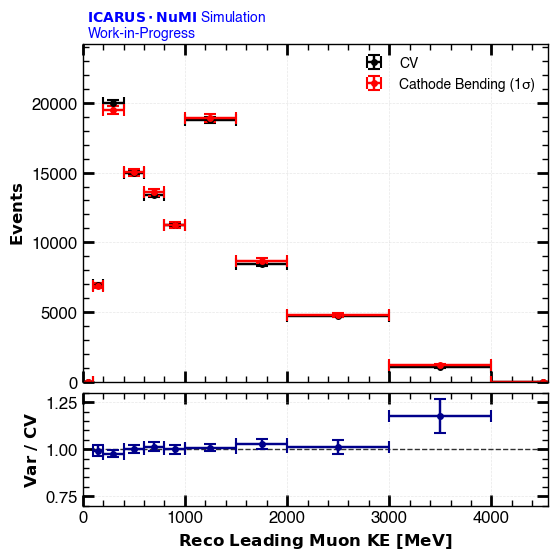

In [5]:
for var_key, info in VAR_INFO.items():
    plot_variation(var_key, info)

## Var/CV check: are the CV and detector-variation samples consistent?
Compares POT-normalized yields and reco visible energy between `cv` and each variation in the medulla file.
Uses the **corrected POT** from `NuMI_nu_mu_systematics.toml` (`pot_override`, failed SPINE subruns removed) and also shows the raw POT stored in the file.

In [6]:
# ── Setup: samples, raw vs corrected POT ───────────────────────────────
import uproot, numpy as np, matplotlib.pyplot as plt
try:
    plt.style.use(STYLE_PATH)
except Exception as e:
    print("style not loaded:", e)

MEDULLA_PATH = ("/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/"
                "🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection/"
                "data/1muNp0pi_Nge1_uncontained.root")
fm = uproot.open(MEDULLA_PATH)

SAMPLES = ['var01p','var01m','var02p','var02m','var03p','var03m','var04p','var04m',
           'var05','var06','var07','var08','var09']
NAMES = {'var01p':'induction_high','var01m':'induction_low','var02p':'coherent_high','var02m':'coherent_low',
         'var03p':'intrinsic_high','var03m':'intrinsic_low','var04p':'lifetime_high','var04m':'lifetime_low',
         'var05':'scintillation','var06':'wire_gap','var07':'yz_uniformity','var08':'recombination','var09':'cathode_bend'}

# raw POT stored in the file
POT_RAW = {s: float(fm[f"events/{s}/POT"].to_numpy()[0].sum()) for s in ['cv'] + SAMPLES}

# corrected POT = pot_override in systematics/toml/NuMI_nu_mu_systematics.toml (same order as pot_override_keys)
_keys = ['cv','var01p','var01m','var02p','var02m','var03p','var03m','var04p','var04m','var05','var06','var07','var08','var09']
_vals = [3.268964080664518e+20, 2.177393489197075e+20, 2.109961693016327e+20, 2.089502366678332e+20,
         2.146904146627747e+20, 1.362680301821289e+20, 2.123722826697954e+20, 2.122939113063286e+20,
         2.159145199417332e+20, 2.162811030648159e+20, 2.104380578726098e+20, 1.922854976729603e+20,
         1.632116696073414e+20, 1.908296197838628e+20]
POT_CORR = dict(zip(_keys, _vals))

print(f"{'sample':8s}{'name':16s}{'POT raw':>11s}{'POT corr':>11s}{'corr/raw':>10s}")
for s in ['cv'] + SAMPLES:
    print(f"{s:8s}{NAMES.get(s,'CV'):16s}{POT_RAW[s]:11.4e}{POT_CORR[s]:11.4e}{POT_CORR[s]/POT_RAW[s]:10.3f}")

sample  name                POT raw   POT corr  corr/raw
cv      CV               3.3122e+20 3.2690e+20     0.987
var01p  induction_high   2.1774e+20 2.1774e+20     1.000
var01m  induction_low    2.1100e+20 2.1100e+20     1.000
var02p  coherent_high    2.1039e+20 2.0895e+20     0.993
var02m  coherent_low     2.1469e+20 2.1469e+20     1.000
var03p  intrinsic_high   1.3697e+20 1.3627e+20     0.995
var03m  intrinsic_low    2.1237e+20 2.1237e+20     1.000
var04p  lifetime_high    2.1382e+20 2.1229e+20     0.993
var04m  lifetime_low     2.1591e+20 2.1591e+20     1.000
var05   scintillation    2.1628e+20 2.1628e+20     1.000
var06   wire_gap         2.1044e+20 2.1044e+20     1.000
var07   yz_uniformity    1.9234e+20 1.9229e+20     1.000
var08   recombination    1.6321e+20 1.6321e+20     1.000
var09   cathode_bend     2.0728e+20 1.9083e+20     0.921


(N_var/POT_var) / (N_cv/POT_cv), corrected POT
sample            preselection      selected      sideband        signal
induction_high           0.993         1.001         0.990         1.003
induction_low            0.996         1.009         0.980         1.001
coherent_high            0.991         1.005         0.989         1.002
coherent_low             0.994         1.002         0.981         1.002
intrinsic_high           0.990         0.997         0.983         0.995
intrinsic_low            0.992         1.004         0.976         1.003
lifetime_high            0.987         0.995         0.999         1.001
lifetime_low             0.990         0.997         1.001         1.004
scintillation            0.995         1.005         0.978         1.004
wire_gap                 0.987         0.996         0.986         0.976
yz_uniformity            0.987         0.986         0.978         1.004
recombination            0.966         0.970         0.999         0.985
cath

/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_49427/792201239.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


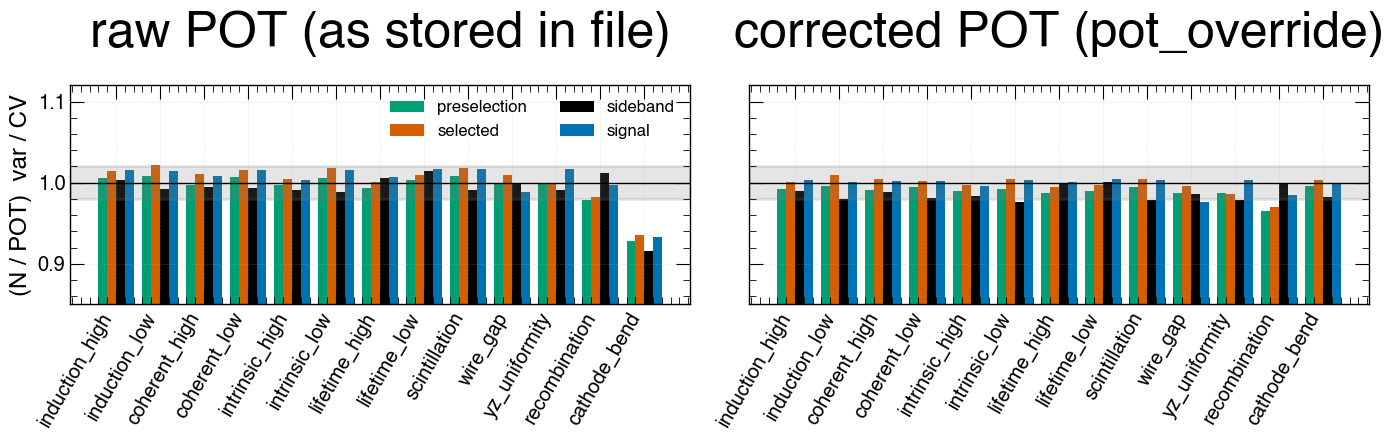

In [7]:
# ── Yield per POT relative to CV, for every tree ────────────────────────
TREES = ['preselection', 'selected', 'sideband', 'signal']
NENT = {(s, t): fm[f"events/{s}/{t}"].num_entries for s in ['cv'] + SAMPLES for t in TREES}

def yield_ratio(s, tree, pot):
    return (NENT[(s, tree)] / pot[s]) / (NENT[('cv', tree)] / pot['cv'])

print("(N_var/POT_var) / (N_cv/POT_cv), corrected POT")
print(f"{'sample':16s}" + "".join(f"{t:>14s}" for t in TREES))
for s in SAMPLES:
    print(f"{NAMES[s]:16s}" + "".join(f"{yield_ratio(s, t, POT_CORR):14.3f}" for t in TREES))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
x = np.arange(len(SAMPLES)); w = 0.2
for ax, pot, ttl in zip(axs, [POT_RAW, POT_CORR], ["raw POT (as stored in file)", "corrected POT (pot_override)"]):
    for i, t in enumerate(TREES):
        ax.bar(x + (i - 1.5) * w, [yield_ratio(s, t, pot) for s in SAMPLES], w, label=t)
    ax.axhline(1.0, color='k', lw=1)
    ax.axhspan(0.98, 1.02, color='grey', alpha=0.2)
    ax.set_xticks(x); ax.set_xticklabels([NAMES[s] for s in SAMPLES], rotation=60, ha='right')
    ax.set_title(ttl); ax.set_ylim(0.85, 1.12); ax.grid(alpha=0.3)
axs[0].set_ylabel("(N / POT)  var / CV"); axs[0].legend(ncol=2)
plt.tight_layout(); plt.show()

/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_49427/2928306949.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


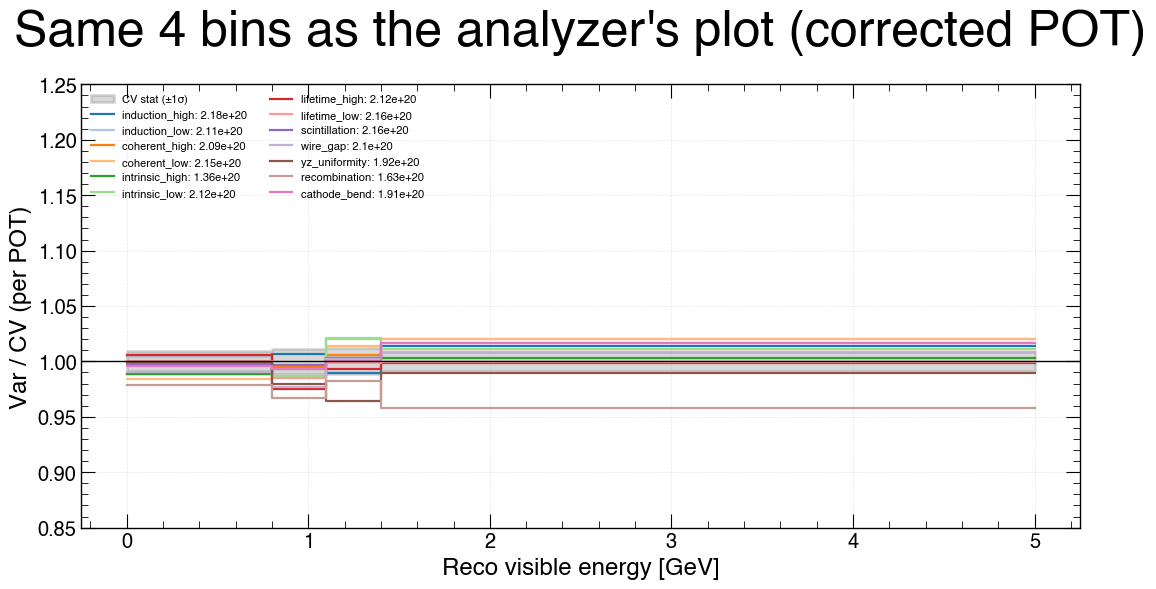

In [8]:
# ── Reco visible energy: Var/CV per POT, analyzer's 4 bins ───────────────
def load_evis(s):
    return fm[f"events/{s}/selected"].arrays(['reco_visible_energy'], library='np')['reco_visible_energy']

EVIS = {s: load_evis(s) for s in ['cv'] + SAMPLES}
cmap = plt.get_cmap('tab20')

def ratio_plot(edges, pot, title, ax, shape_only=False):
    cvh, _ = np.histogram(EVIS['cv'], edges)
    cv_scale = 1.0 / pot['cv']
    if shape_only: cv_scale = 1.0 / cvh.sum()
    cv_norm = cvh * cv_scale
    cv_rel_err = 1.0 / np.sqrt(np.maximum(cvh, 1))
    ax.fill_between(np.repeat(edges, 2)[1:-1],
                    np.repeat(1 - cv_rel_err, 2), np.repeat(1 + cv_rel_err, 2),
                    color='grey', alpha=0.3, label=f"CV stat (±1σ)")
    for i, s in enumerate(SAMPLES):
        h, _ = np.histogram(EVIS[s], edges)
        sc = (1.0 / h.sum()) if shape_only else (1.0 / pot[s])
        with np.errstate(divide='ignore', invalid='ignore'):
            r = (h * sc) / cv_norm
            ax.step(edges, np.append(r, r[-1]), where='post', color=cmap(i), lw=1.6,
                label=f"{NAMES[s]}: {pot[s]:.3g}")
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xlabel("Reco visible energy [GeV]")
    ax.set_ylabel("Var / CV (area-normalized)" if shape_only else "Var / CV (per POT)")
    ax.set_title(title); ax.grid(alpha=0.3)

EDGES4 = np.array([0, 0.8, 1.1, 1.4, 5.0])
fig, ax = plt.subplots(figsize=(11, 6))
ratio_plot(EDGES4, POT_CORR, "Same 4 bins as the analyzer's plot (corrected POT)", ax)
ax.set_ylim(0.85, 1.25); ax.legend(fontsize=8, ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

/var/folders/hn/gg8vh0yd4j1382jb74b5wr780000gn/T/ipykernel_49427/2380611267.py:8: UserWarning: The figure layout has changed to tight
  plt.tight_layout(); plt.show()


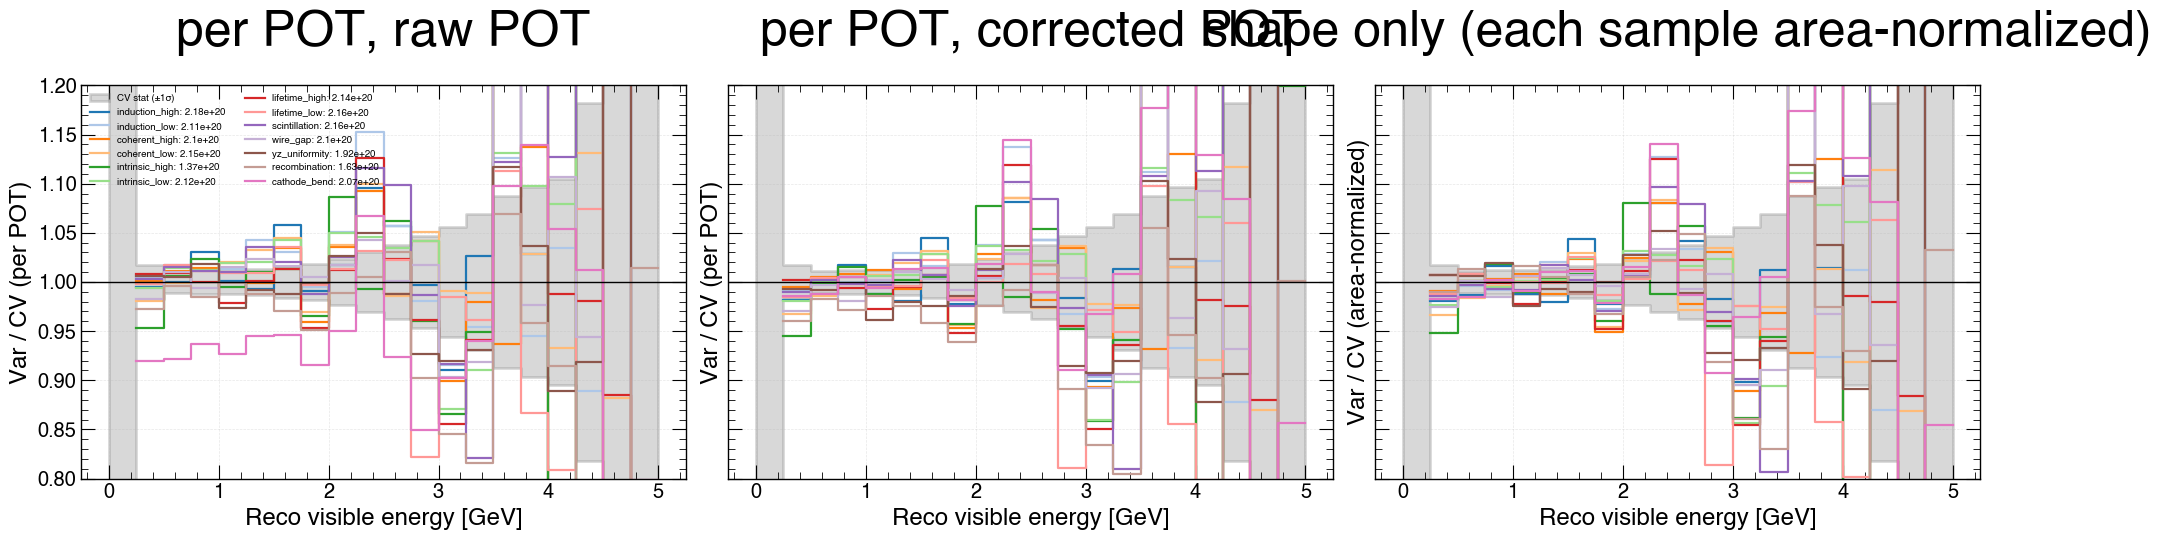

In [9]:
# ── Finer binning, raw vs corrected POT, and shape-only ────────────────
EDGES20 = np.linspace(0, 5, 21)
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
ratio_plot(EDGES20, POT_RAW,  "per POT, raw POT", axs[0])
ratio_plot(EDGES20, POT_CORR, "per POT, corrected POT", axs[1])
ratio_plot(EDGES20, POT_CORR, "shape only (each sample area-normalized)", axs[2], shape_only=True)
axs[0].set_ylim(0.8, 1.2); axs[0].legend(fontsize=7, ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

In [10]:
# ── Event counts per bin (to judge the stat error of each bin) ─────────
cvh4, _ = np.histogram(EVIS['cv'], EDGES4)
print("CV counts in analyzer bins:", cvh4, " -> relative stat err:", np.round(1/np.sqrt(cvh4), 4))
print(f"{'sample':16s}" + "".join(f"  bin{i}" for i in range(4)) + "   <- Var/CV per POT (corrected)")
for s in SAMPLES:
    h, _ = np.histogram(EVIS[s], EDGES4)
    r = (h / POT_CORR[s]) / (cvh4 / POT_CORR['cv'])
    print(f"{NAMES[s]:16s}" + "".join(f"  {v:.3f}" for v in r))

CV counts in analyzer bins: [12099  8340  7337 13993]  -> relative stat err: [0.0091 0.011  0.0117 0.0085]
sample            bin0  bin1  bin2  bin3   <- Var/CV per POT (corrected)
induction_high    0.988  1.006  0.990  1.014
induction_low     1.004  0.987  1.021  1.020
coherent_high     1.006  0.995  1.005  1.009
coherent_low      0.984  0.986  1.014  1.021
intrinsic_high    0.989  0.994  1.003  1.003
intrinsic_low     0.999  0.987  1.020  1.011
lifetime_high     1.006  0.975  0.993  0.999
lifetime_low      1.000  0.985  0.998  1.000
scintillation     0.997  0.996  1.003  1.017
wire_gap          0.990  0.977  1.003  1.008
yz_uniformity     0.999  0.980  0.964  0.989
recombination     0.979  0.967  0.982  0.958
cathode_bend      0.996  0.993  1.001  1.016
